In [1]:
import numpy as np
import torch
import torch.nn as nn
import yfinance as yf
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

In [2]:
# hyperparameters
train_test_prop = 0.8
batch_size = 16
block_size = 8 # the temporal block size of the model
epochs = 100
learning_rate = 0.0001
device = 'cuda' if torch.cuda.is_available() else 'cpu'
show_stats = True

# model parameters
n_hidden = 128
n_layer = 2
dropout = 0.2

torch.manual_seed(1337)

In [3]:
data = yf.download("AMZN")
data.columns = data.columns.droplevel(1)
# data = data["2020-01-01":]

[*********************100%***********************]  1 of 1 completed


In [4]:
data["1D Return"] = data["Close"].pct_change(1)
data["5D Return"] = data["Close"].pct_change(5)
data["20D Return"] = data["Close"].pct_change(20)
data["80D Return"] = data["Close"].pct_change(80)
data["120D Return"] = data["Close"].pct_change(120)
data["160D Return"] = data["Close"].pct_change(160)
data["200D Return"] = data["Close"].pct_change(200)
data["20D EMA"] = data["Close"].ewm(span=20, adjust=False).mean()
data["80D EMA"] = data["Close"].ewm(span=80, adjust=False).mean()
data["120D EMA"] = data["Close"].ewm(span=120, adjust=False).mean()
data["160D EMA"] = data["Close"].ewm(span=160, adjust=False).mean()
data["200D EMA"] = data["Close"].ewm(span=200, adjust=False).mean()
data.dropna(inplace=True)

In [5]:
data.drop(columns=["Close", "Adj Close", "Open", "High", "Low", "Volume"], inplace=True)
data

Price,1D Return,5D Return,20D Return,80D Return,120D Return,160D Return,200D Return,20D EMA,80D EMA,120D EMA,160D EMA,200D EMA
Date,,,,,,,,,,,,
1998-03-03,-0.059016,0.105970,0.150299,0.205879,0.845659,1.799993,2.053178,0.275335,0.240753,0.223152,0.208131,0.195756
1998-03-04,0.023522,0.114803,0.188071,0.255344,0.853317,1.510687,2.539175,0.278254,0.242364,0.224522,0.209347,0.196852
1998-03-05,0.021275,0.030928,0.234568,0.340782,0.980192,1.678564,2.658522,0.281516,0.244096,0.225976,0.210628,0.198003
1998-03-06,0.023334,-0.003245,0.295360,0.427911,0.734465,1.882619,2.910824,0.285161,0.245965,0.227527,0.211984,0.199215
1998-03-09,0.087948,0.095084,0.418257,0.653464,1.249153,2.227041,3.875928,0.291138,0.248482,0.229516,0.213673,0.200695
...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-20,0.007300,-0.011167,0.133784,0.316862,0.124600,0.207884,0.272028,220.113396,202.257927,196.341309,191.527283,187.144621
2024-12-23,0.000622,-0.033787,0.141741,0.307576,0.139025,0.192687,0.283490,220.584501,202.820941,196.815998,191.943838,187.521888
2024-12-24,0.017729,-0.009085,0.137007,0.283193,0.145250,0.213446,0.331996,221.390739,203.468572,197.348791,192.404784,187.935104


In [6]:
split_index = int(data.shape[0] * train_test_prop)
train_x = data.iloc[:split_index]
test_x = data.iloc[split_index:]
train_y = train_x["1D Return"].shift(-1).dropna()
test_y = test_x["1D Return"].shift(-1).dropna()
train_x = train_x.loc[train_y.index]
test_x = test_x.loc[test_y.index]
assert train_x.index.equals(train_y.index)
assert test_x.index.equals(test_y.index)

train_x.shape, train_y.shape, test_x.shape, test_y.shape

((5399, 12), (5399,), (1350, 12), (1350,))

In [7]:
# scaler = StandardScaler()
# scaler.fit(train_x)
# train_x = scaler.transform(train_x)
# test_x = scaler.transform(test_x)
train_x = train_x.to_numpy()
test_x = test_x.to_numpy()

In [8]:
class TimeSeriesDataset(Dataset):
    def __init__(self, x, y, block_size):
        self.x = x
        self.y = y
        self.block_size = block_size

    def __len__(self):
        return len(self.y) - self.block_size + 1

    def __getitem__(self, idx):
        if idx + self.block_size > len(self.x):
            raise IndexError("Index out of bounds")
        return (
            torch.tensor(self.x[idx:idx+self.block_size], dtype=torch.float32),
            torch.tensor(self.y[idx+self.block_size-1], dtype=torch.float32).unsqueeze(-1)
        )

In [9]:
train_dataset = TimeSeriesDataset(train_x, train_y.to_numpy(), block_size)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

test_dataset = TimeSeriesDataset(test_x, test_y.to_numpy(), block_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [10]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, dropout):
        super(LSTMModel, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=dropout)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x: (batch_size, block_size, feature_size)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_().to(device)

        # Initialize cell state
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).requires_grad_().to(device)

        # We need to detach as we are doing truncated backpropagation through time (BPTT)
        # If we don't, we'll backprop all the way to the start even after going through another batch
        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        
        # out: (batch_size, block_size, hidden_size), contains all hidden states in block_size. We only want the last one.
        out = self.fc(out[:, -1, :]) 

        # out: (batch_size, 1)
        return out
    

In [ ]:
model = LSTMModel(input_size=train_x.shape[1], hidden_size=n_hidden, num_layers=n_layer, dropout=dropout)
model.to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [20]:
def run_epoch(model, criterion, loader, optimizer, is_train):
    if is_train:
        model.train()
    else:
        model.eval()
    
    epoch_loss = 0
    total_samples = 0

    for x, y in loader:
        if is_train:
            optimizer.zero_grad()
        
        x = x.to(device)
        y = y.to(device)
        
        batchsize = x.shape[0]
                            
        out = model(x)
        loss = criterion(out, y)

        if is_train:
            loss.backward()
            optimizer.step()

        epoch_loss += loss.item() * batchsize
        total_samples += batchsize
        #potential idea: only get validation loss every x epochs?
    
    return epoch_loss / total_samples


In [21]:
train_losses = np.zeros(epochs)
test_losses = np.zeros(epochs)

for epoch in tqdm(range(epochs)):
    train_loss = run_epoch(model, criterion, train_loader, optimizer, is_train=True)
    test_loss = run_epoch(model, criterion, test_loader, optimizer, is_train=False)
    train_losses[epoch] = train_loss
    test_losses[epoch] = test_loss

    if show_stats:
        tqdm.write(f"\rEpoch[{epoch+1}/{epochs}] | loss train: {train_loss}, test: {test_loss}", end="\r")


  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\luis\Documents\GitHub\QTG\.venv\Lib\site-packages\torch\nn\modules\loss.py:608: UserWarning: Using a target size (torch.Size([16, 1])) that is different to the input size (torch.Size([16, 8, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


RuntimeError: The size of tensor a (8) must match the size of tensor b (16) at non-singleton dimension 1

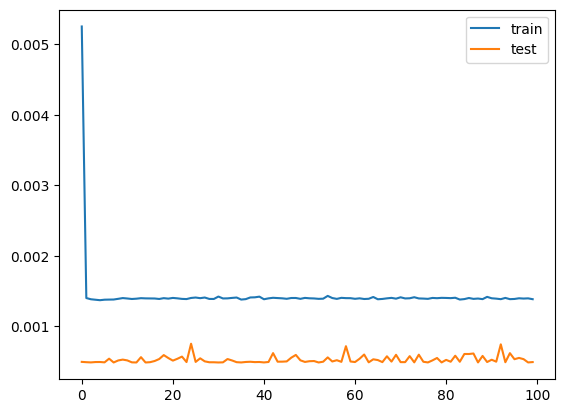

In [14]:
plt.plot(train_losses, label='train')

plt.plot(test_losses, label='test')

plt.legend()

plt.show()
